# 04 · Mô hình Bohr và phổ hydro / The Bohr model and hydrogen’s spectrum

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/04_bohr.ipynb)

Từ hằng số cơ bản đến vạch phổ; so với số đo chân không, rồi kiểm tra giới hạn cổ điển. Chạy lần lượt từ trên xuống. Dữ liệu NIST được chép sẵn để chạy không cần mạng.
*From fundamental constants to spectral lines; compare with vacuum measurements, then test the classical limit. Run the cells in order. NIST data are embedded for offline use.*

Mô hình một electron, phi tương đối tính: có khối lượng rút gọn, chưa có cấu trúc tinh tế, Lamb shift hay cấu trúc siêu tinh tế.
*One-electron, non-relativistic model: reduced mass is included; fine structure, the Lamb shift and hyperfine structure are omitted.*

## 1. Hằng số Rydberg / The Rydberg constant

Với hạt nhân nặng vô hạn: $R_\infty=m_e e^4/(8\varepsilon_0^2 h^3c)$. Với khối lượng hạt nhân $M$, thay $m_e$ bằng $\mu=m_eM/(m_e+M)$, nên $R_M=R_\infty/(1+m_e/M)$.
*For an infinitely heavy nucleus use $R_\infty$ above. For nuclear mass $M$, replace $m_e$ with the reduced mass $\mu$, giving $R_M=R_\infty/(1+m_e/M)$.*

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import m_e, m_p, e, epsilon_0, h, c, Rydberg, physical_constants
from scipy.integrate import solve_ivp
from IPython.display import display, Markdown

R_inf = m_e * e**4 / (8 * epsilon_0**2 * h**3 * c)
R_H = R_inf / (1 + m_e / m_p)
a0 = 4 * np.pi * epsilon_0 * (h / (2 * np.pi))**2 / (m_e * e**2)
r_e = e**2 / (4 * np.pi * epsilon_0 * m_e * c**2)
assert abs(R_inf / Rydberg - 1) < 1e-10
print(f"Derived R_infinity = {R_inf:.6f} m^-1")
print(f"scipy Rydberg      = {Rydberg:.6f} m^-1")
print(f"Relative difference = {R_inf / Rydberg - 1:.3e}")
print(f"Reduced-mass R_H   = {R_H:.6f} m^-1")
print(f"Hydrogen E_1       = {-h * c * R_H / e:.8f} eV")

def wavelength(upper, lower, Z=1, mass=m_p):
    """Vacuum nm; mass is the nuclear mass in kg, not the atomic mass."""
    R = R_inf / (1 + m_e / mass)
    return 1e9 / (Z**2 * R * (1 / lower**2 - 1 / upper**2))

def table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))

Derived R_infinity = 10973731.568138 m^-1
scipy Rydberg      = 10973731.568157 m^-1
Relative difference = -1.751e-12
Reduced-mass R_H   = 10967758.340258 m^-1
Hydrogen E_1       = -13.59828726 eV


## 2. So với NIST / Comparison with NIST

[NIST ASD v5.12](https://physics.nist.gov/asd), H I, đơn vị nm, **vacuum**, cột **Observed** (không dùng cột Ritz). Bốn vạch Balmer dưới đây cũng là bảng trong `sims/bohr.js`. Các hàng chỉ ghi số lượng tử chính là các vạch chưa phân giải; không trộn chúng với một thành phần cấu trúc tinh tế riêng lẻ.
*[NIST ASD v5.12](https://physics.nist.gov/asd), H I, nm, **vacuum**, **Observed** column (rather than Ritz). The four Balmer entries are also the table in `sims/bohr.js`. Principal-quantum-number-only rows describe unresolved lines; do not mix these with individual fine-structure components.*

[Truy vấn / Query](https://physics.nist.gov/cgi-bin/ASD/lines1.pl?spectra=H%20I&unit=1&show_av=3&show_obs_wl=1&show_calc_wl=1) · [Bản lưu kết quả NIST / Archived NIST output](https://viewvc.nublado.org/nist/asd_v5.12/lines/asd.001000).

Sai số tương đối bên dưới là (Bohr − số đo) / số đo. Dấu ± là độ bất định mà ASD liệt kê, không phải độ chính xác của mô hình.
*Relative error below is (Bohr − observed) / observed. The ± values are ASD’s listed uncertainties, not the accuracy of the model.*

| Line | Jump | NIST vacuum (nm) | Bohr vacuum (nm) | Relative error |
| --- | --- | --- | --- | --- |
| Lyman α | 2 → 1 | 121.56701 ± 0.00021 | 121.56845 | +0.001181% |
| Lyman β | 3 → 1 | 102.57280 ± 0.0003 | 102.57338 | +0.000562% |
| Lyman γ | 4 → 1 | 97.25170 ± 0.0014 | 97.25476 | +0.003143% |
| Hα | 3 → 2 | 656.46000 ± 0.003 | 656.46961 | +0.001463% |
| Hβ | 4 → 2 | 486.27100 ± 0.005 | 486.27378 | +0.000572% |
| Hγ | 5 → 2 | 434.16920 ± 0.0006 | 434.17302 | +0.000880% |
| Hδ | 6 → 2 | 410.28920 ± 0.0006 | 410.29350 | +0.001049% |
| Paschen α | 4 → 3 | 1875.64000 ± 0.1 | 1875.62745 | -0.000669% |
| Paschen β | 5 → 3 | 1282.15780 ± 0.0008 | 1282.16720 | +0.000733% |
| Paschen γ | 6 → 3 | 1094.11700 ± 0.013 | 1094.11601 | -0.000090% |

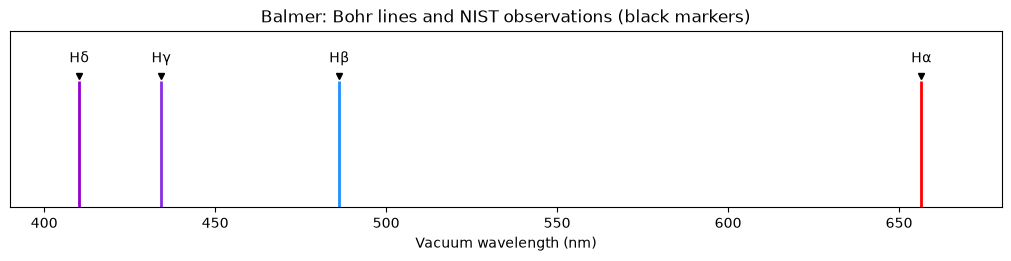

In [2]:
# label, upper, lower, observed vacuum nm, uncertainty nm; NIST ASD Observed column.
# Balmer: L7400c29, L7439c30, L7436c29. Lyman: L12020, L3545, L8834.
# Paschen: L4812, L7421. Source and archived output are linked above.
measured_balmer = [
    ("Hα", 3, 2, 656.460, .003),
    ("Hβ", 4, 2, 486.271, .005),
    ("Hγ", 5, 2, 434.1692, .0006),
    ("Hδ", 6, 2, 410.2892, .0006),
]
measured = [
    ("Lyman α", 2, 1, 121.56701, .00021),
    ("Lyman β", 3, 1, 102.5728, .0003),
    ("Lyman γ", 4, 1, 97.2517, .0014),
    *measured_balmer,
    ("Paschen α", 4, 3, 1875.64, .10),
    ("Paschen β", 5, 3, 1282.1578, .0008),
    ("Paschen γ", 6, 3, 1094.117, .013),
]
rows = []
for name, upper, lower, observed, uncertainty in measured:
    prediction = wavelength(upper, lower)
    error = (prediction / observed - 1) * 100
    rows.append([name, f"{upper} → {lower}", f"{observed:.5f} ± {uncertainty:g}",
                 f"{prediction:.5f}", f"{error:+.6f}%"])
    assert abs(error) < .005

table(["Line", "Jump", "NIST vacuum (nm)", "Bohr vacuum (nm)", "Relative error"], rows)
# Ritz combination is exact for energies in this model, not for wavelengths.
energy = lambda upper, lower: h * c * R_H * (1 / lower**2 - 1 / upper**2)
assert np.isclose(energy(3, 1), energy(3, 2) + energy(2, 1), rtol=1e-12)

fig, ax = plt.subplots(figsize=(10, 2.5), layout="constrained")
for name, upper, lower, observed, uncertainty in measured_balmer:
    predicted = wavelength(upper, lower)
    ax.vlines(predicted, 0, 1, color={"Hα": "red", "Hβ": "dodgerblue", "Hγ": "blueviolet", "Hδ": "darkviolet"}[name], linewidth=2)
    ax.plot(observed, 1.04, "kv", markersize=5)
    ax.text(observed, 1.15, name, ha="center")
ax.set(xlim=(390, 680), ylim=(0, 1.4), yticks=[], xlabel="Vacuum wavelength (nm)",
       title="Balmer: Bohr lines and NIST observations (black markers)")
plt.show()

## 3. Balmer năm 1885 / Balmer in 1885

$\lambda=B m^2/(m^2-4)$ với $B=364{,}56$ nm. Balmer khớp công thức với bước sóng Ångström đo **trong không khí**. Bohr ở đây tính trong chân không. Không nên diễn giải toàn bộ độ lệch này là sai số của lý thuyết.
*$\lambda=B m^2/(m^2-4)$ with $B=364.56$ nm. Balmer fitted Ångström’s **air** wavelengths. Here Bohr’s formula gives vacuum wavelengths; this difference should not all be interpreted as an error in the theory.*

Nguồn / Source: J. J. Balmer, “Notiz über die Spectrallinien des Wasserstoffs”, *Ann. Phys. Chem.* 25, 80 (1885). [NIST giải thích cách đổi không khí–chân không / NIST’s air–vacuum conversion notes](https://physics.nist.gov/PhysRefData/ASD/Html/lineshelp.html).

In [3]:
rows = []
for name, upper, lower, observed, _ in measured_balmer:
    balmer = 364.56 * upper**2 / (upper**2 - 4)
    bohr = wavelength(upper, lower)
    rows.append([name, f"{balmer:.5f}", f"{bohr:.5f}", f"{(balmer / bohr - 1) * 100:+.5f}%"])
    assert abs(balmer / bohr - 1) < .0005
table(["Line", "Balmer 1885: air (nm)", "Bohr: vacuum (nm)", "Difference"], rows)

| Line | Balmer 1885: air (nm) | Bohr: vacuum (nm) | Difference |
| --- | --- | --- | --- |
| Hα | 656.20800 | 656.46961 | -0.03985% |
| Hβ | 486.08000 | 486.27378 | -0.03985% |
| Hγ | 434.00000 | 434.17302 | -0.03985% |
| Hδ | 410.13000 | 410.29350 | -0.03985% |

## 4. Dịch chuyển đồng vị / Isotope shift

Hạt nhân đơteri nặng hơn → khối lượng rút gọn lớn hơn → vạch Hα có bước sóng ngắn hơn khoảng $0{,}18$ nm.
*A heavier deuterium nucleus gives a larger reduced mass and an Hα wavelength shorter by about $0.18$ nm.*

Urey, Brickwedde và Murphy dùng dịch chuyển này để phát hiện đơteri năm 1932: [“A Hydrogen Isotope of Mass 2”, *Phys. Rev.* **39**, 164–165 (1932)](https://doi.org/10.1103/PhysRev.39.164).
*Urey, Brickwedde and Murphy used this shift to discover deuterium in 1932 (citation above).*

In [4]:
m_d = physical_constants["deuteron mass"][0]
h_alpha = wavelength(3, 2)
d_alpha = wavelength(3, 2, mass=m_d)
shift = h_alpha - d_alpha
assert .17 < shift < .19
print(f"Hydrogen Hα:  {h_alpha:.6f} nm (vacuum)")
print(f"Deuterium Dα: {d_alpha:.6f} nm (vacuum)")
print(f"Hα − Dα:       {shift:.6f} nm")

Hydrogen Hα:  656.469606 nm (vacuum)
Deuterium Dα: 656.291030 nm (vacuum)
Hα − Dα:       0.178576 nm


## 5. He⁺ và dãy Pickering / He⁺ and the Pickering series

He⁺ có $Z=2$ và một electron. Dãy Pickering là các bước nhảy từ mức trên $m=5,6,\ldots$ **xuống mức 4**. Với $m$ chẵn, công thức gần trùng với các vạch Balmer; với $m$ lẻ, cách gán cũ cho hydro đòi hỏi số lượng tử bán nguyên.
*He⁺ has $Z=2$ and one electron. Pickering emission comes from upper levels $m=5,6,\ldots$ **down to level 4**. Even $m$ nearly coincide with Balmer lines; odd $m$ would require half-integer quantum numbers under the old hydrogen assignment.*

Fowler phản biện độ lệch nhỏ còn lại; Bohr dùng khối lượng rút gọn riêng cho H và He để sửa tỉ số hằng số Rydberg. So sánh cột dùng nhầm $R_H$ cho cả hai với cột dùng khối lượng hạt nhân heli thật.
*Fowler challenged the remaining small discrepancy. Bohr used separate reduced masses for H and He to correct the ratio of their Rydberg constants. Compare the column incorrectly using $R_H$ for both species with the helium-nucleus result.*

Nguồn / Source: N. Bohr, [“The spectra of helium and hydrogen”, *Nature* **92**, 231–232 (1913)](https://doi.org/10.1038/092231d0); A. Fowler, *Nature* **92**, 95 (1913).

In [5]:
m_alpha = physical_constants["alpha particle mass"][0]  # Bare He-4 nucleus, not a helium atom.
R_He = R_inf / (1 + m_e / m_alpha)
rows = []
for upper in range(5, 11):
    fixed = wavelength(upper, 4, Z=2, mass=np.inf)
    wrong = wavelength(upper, 4, Z=2, mass=m_p)
    corrected = wavelength(upper, 4, Z=2, mass=m_alpha)
    rows.append([f"{upper} → 4", f"{upper / 2:g} → 2", f"{fixed:.5f}",
                 f"{wrong:.5f}", f"{corrected:.5f}", f"{wrong - corrected:.5f}"])
table(["He⁺ jump", "Old H assignment", "Fixed nucleus (nm)",
       "Using R_H (nm)", "He reduced mass (nm)", "Correction (nm)"], rows)
print(f"R_He / R_H = {R_He / R_H:.9f}")
assert 1.0004 < R_He / R_H < 1.00042

| He⁺ jump | Old H assignment | Fixed nucleus (nm) | Using R_H (nm) | He reduced mass (nm) | Correction (nm) |
| --- | --- | --- | --- | --- | --- |
| 5 → 4 | 2.5 → 2 | 1012.51895 | 1013.07038 | 1012.65775 | 0.41263 |
| 6 → 4 | 3 → 2 | 656.11228 | 656.46961 | 656.20223 | 0.26738 |
| 7 → 4 | 3.5 → 2 | 541.23740 | 541.53217 | 541.31160 | 0.22057 |
| 8 → 4 | 4 → 2 | 486.00909 | 486.27378 | 486.07572 | 0.19806 |
| 9 → 4 | 4.5 → 2 | 454.23158 | 454.47896 | 454.29385 | 0.18511 |
| 10 → 4 | 5 → 2 | 433.93669 | 434.17302 | 433.99618 | 0.17684 |

R_He / R_H = 1.000407468


## 6. Electron cổ điển rơi vào hạt nhân / Classical collapse

Quỹ đạo tròn có $E=-e^2/(8\pi\varepsilon_0 r)$, gia tốc $a=e^2/(4\pi\varepsilon_0m_e r^2)$ và công suất Larmor $P=e^2a^2/(6\pi\varepsilon_0c^3)$.
*A circular orbit has energy $E$, acceleration $a$ and Larmor power $P$ as above.*

Từ $\dot E=-P$, suy ra $\dot r=-4r_e^2c/(3r^2)$ và $t_c=a_0^3/(4r_e^2c)$. Đặt $u=r/a_0$, $\tau=t/t_c$ để tích phân ổn định bằng `solve_ivp`: $du/d\tau=-1/(3u^2)$.
*From $\dot E=-P$, obtain the radial loss rate and collapse time above. Scale to $u=r/a_0$, $\tau=t/t_c$ for stable integration with `solve_ivp`.*

Dừng ở $r=0{,}01a_0$ để tránh điểm kỳ dị, rồi cộng thời gian giải tích còn lại $t_cu^3$. Đây là mô hình cổ điển phi tương đối tính với quỹ đạo gần tròn, không phải mô tả nguyên tử thật.
*Stop at $r=0.01a_0$ to avoid the singularity, then add the remaining analytic time $t_cu^3$. This is a non-relativistic classical, quasi-circular model, not a description of a real atom.*

Analytic t_c:          1.556177463e-11 s
Integrated + tail:     1.556177463e-11 s
Relative difference:   -3.092e-13


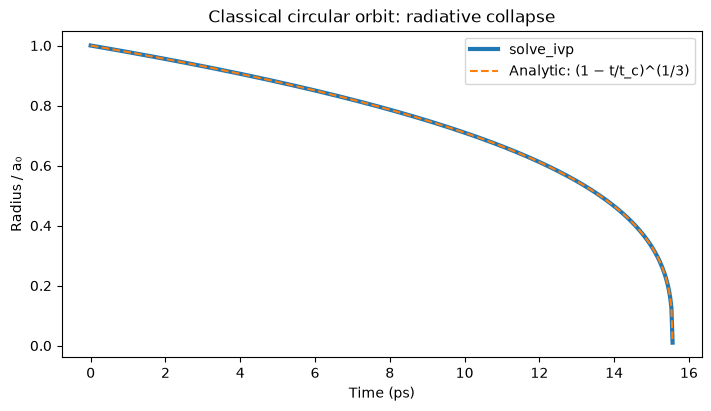

In [6]:
t_c = a0**3 / (4 * r_e**2 * c)
cutoff = .01

def radial_loss(tau, state):
    # dr/dt from Coulomb energy and Larmor power, scaled to u and tau.
    return [-(4 / 3) * r_e**2 * c * t_c / a0**3 / state[0]**2]

def small_radius(tau, state):
    return state[0] - cutoff

small_radius.terminal = True
small_radius.direction = -1
solution = solve_ivp(radial_loss, (0, 1.001), [1.0], method="DOP853",
                     events=small_radius, rtol=1e-10, atol=1e-12, dense_output=True, max_step=.01)
assert solution.success and len(solution.t_events[0]) == 1
stop = solution.t_events[0][0]
numerical_collapse = (stop + cutoff**3) * t_c
relative_error = numerical_collapse / t_c - 1
assert abs(relative_error) < 1e-8
assert 1.5e-11 < t_c < 1.6e-11
print(f"Analytic t_c:          {t_c:.9e} s")
print(f"Integrated + tail:     {numerical_collapse:.9e} s")
print(f"Relative difference:   {relative_error:+.3e}")

sample_tau = np.linspace(0, stop, 500)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(sample_tau * t_c * 1e12, solution.sol(sample_tau)[0], label="solve_ivp", linewidth=3)
ax.plot(sample_tau * t_c * 1e12, np.cbrt(1 - sample_tau), "--", label="Analytic: (1 − t/t_c)^(1/3)")
ax.set(xlabel="Time (ps)", ylabel="Radius / a₀", title="Classical circular orbit: radiative collapse")
ax.legend()
plt.show()

## 7. Thử thêm / Try this

- Đổi mức dưới từ 2 sang 1 hoặc 3: vạch nào ra khỏi vùng nhìn thấy? Tính cả giới hạn $m\to\infty$.
  *Change the lower level from 2 to 1 or 3: which lines move outside the visible range? Calculate the $m\to\infty$ limit too.*
- Thay khối lượng hạt nhân bằng vô hạn, proton hoặc đơteron: sai số bước sóng thay đổi bao nhiêu? Giữ rõ đơn vị và loại hạt nhân.
  *Use an infinite, proton or deuteron nuclear mass: how much do the wavelengths change? Keep the units and nuclear species explicit.*
- Vẽ dãy Pickering và Balmer trên cùng trục: vì sao chỉ một số vạch gần trùng nhau?
  *Plot Pickering and Balmer lines together: why do only some nearly coincide?*
- Tăng bán kính ban đầu gấp đôi trong phép tích phân cổ điển: thời gian rơi tăng bao nhiêu? So với quy luật $t_c\propto r_0^3$.
  *Double the initial classical orbital radius: how much longer does collapse take? Compare with $t_c\propto r_0^3$.*